## **소음 실험 음압 분석 및 FFT**

기계시스템공학실험(B) 동제어 1주차

---
`df_94db`: 캘리브레이터로 생성한 94dB의 음향신호 데이터

`df_114db`: 캘리브레이터로 생성한 114dB의 음향신호 데이터

`df_noise` : 여러 신호가 섞인 음향신호 데이터

모든 데이터에서 시간 간격 3.906250E-5 sec, 단위 Pa
<br><br>

실험 분석을 위해 사용한 라이브러리 및 용도는 다음과 같습니다.


`pandas`: csv 형태의 데이터를 처리하기 위해 사용하였다.

`matplotlib`: Python의 시각화 라이브러리로, 각종 그래프의 시각화를 위해 사용하였다.

`numpy`: 각 데이터의 FFT(푸리에 변환)을 위해 사용하였다. 

<br><br>
이외 자세한 실험 과정 및 결과는 실험 보고서를 참고 바랍니다.

### **데이터 불러오기 및 전처리**

모든 데이터에서 시간 간격 3.906250E-5 sec, 단위 Pa이다.

데이터에 시간(Time)열을 추가하고, 칼럼명 각각 Time, Sound로 설정한다.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import matplotlib

plt.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus'] = False

df_noise = pd.read_excel("D:/00 기계공학실험/동제어/noise_experiment_timedomain.xlsx", header=None)
df_94db = pd.read_excel("D:/00 기계공학실험/동제어/캘리브레이터_94dB_timedomain.xlsx", header=None)
df_114db = pd.read_excel("D:/00 기계공학실험/동제어/캘리브레이터_114dB_timedomain.xlsx", header=None)

df_noise.columns = ['Sound']
dt = 3.906250E-5  # 주어진 시간 간격
time_array = np.arange(len(df_noise)) * dt
df_noise.insert(0, 'Time', time_array)

df_94db.columns = ['Sound']
time_array = np.arange(len(df_noise)) * dt
df_94db.insert(0, 'Time', time_array)

df_114db.columns = ['Sound']
time_array = np.arange(len(df_noise)) * dt
df_114db.insert(0, 'Time', time_array)

display(df_noise.head())

,Time,Sound
0,0.000000,-0.174998
1,0.000039,-0.300346
2,0.000078,-0.437059
3,0.000117,-0.686826
4,0.000156,-0.966454


In [5]:
display(df_94db.head())
display(df_114db.head())

,Time,Sound
0,0.000000,0.230995
1,0.000039,0.317210
2,0.000078,0.386028
3,0.000117,0.431416
4,0.000156,0.449438


,Time,Sound
0,0.000000,4.490182
1,0.000039,4.357864
2,0.000078,3.961081
3,0.000117,3.324552
4,0.000156,2.487672


### **캘리브레이션 실험**

캘리브레이터로 발생한 94dB, 114dB의 신호에 대한 분석

Signal Period: 0.001001 sec


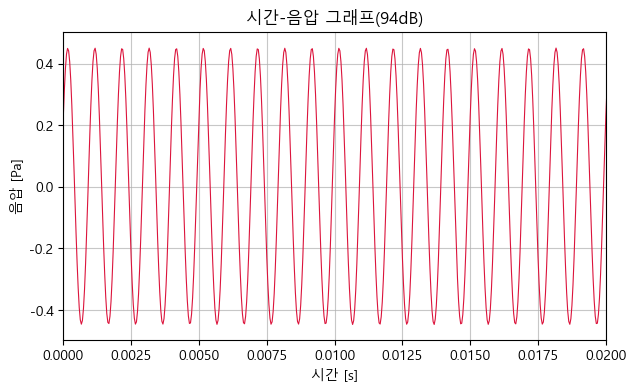

In [19]:
## 시간축 주기 계산
dt = df_94db['Time'].iloc[1] - df_94db['Time'].iloc[0]
N = len(df_94db)
fft_vals = np.fft.fft(df_94db['Sound'] - df_94db['Sound'].mean())
freqs = np.fft.fftfreq(N, dt)
pos = freqs >= 0
amp = np.abs(fft_vals[pos])
peak_freq = freqs[pos][np.argmax(amp[freqs[pos] > 0])]
signal_period = 1 / peak_freq

print(f"Signal Period: {signal_period:.6f} sec")

## 시간축 그래프 그리기
plt.figure(figsize=(7, 4))
plt.plot(df_94db['Time'], df_94db['Sound'], color='crimson', linewidth=0.8)
plt.xlim((0,0.02))
plt.title('시간-음압 그래프(94dB)')
plt.xlabel('시간 [s]')
plt.ylabel('음압 [Pa]')
plt.grid(True, alpha=0.7)
plt.show()

Peak Frequency: 1000.00 Hz | Amplitude: 0.4474 Pa


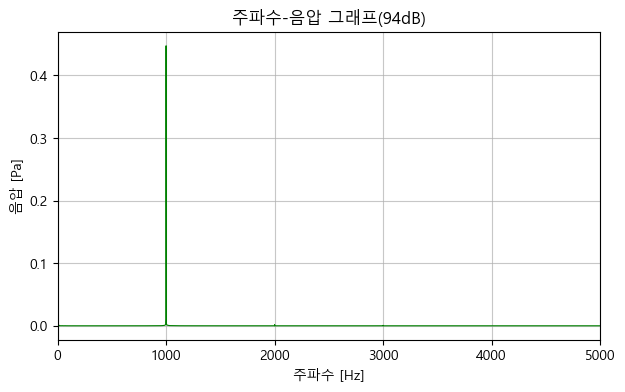

In [23]:
## FFT 진행
N = len(df_94db)
dt = df_94db['Time'].iloc[1] - df_94db['Time'].iloc[0]
fft_vals = np.fft.fft(df_94db['Sound'] - df_94db['Sound'].mean())
freqs = np.fft.fftfreq(N, dt)
pos = freqs >= 0
amp = (2.0 / N) * np.abs(fft_vals[pos])
amp[0] /= 2.0
f, a = freqs[pos], amp
peak_idx = np.argmax(a[f > 0])
peak_freq = f[f > 0][peak_idx]
peak_amp = a[f > 0][peak_idx]
print(f"Peak Frequency: {peak_freq:.2f} Hz | Amplitude: {peak_amp:.4f} Pa")

## 주파수축 그래프 그리기
plt.figure(figsize=(7, 4))
plt.title('주파수-음압 그래프(94dB)')
plt.plot(f, a, color='green', linewidth=0.8)
plt.xlabel('주파수 [Hz]')
plt.ylabel('음압 [Pa]')
plt.grid(True, alpha=0.7)
plt.xlim(0, 5000)
plt.show()

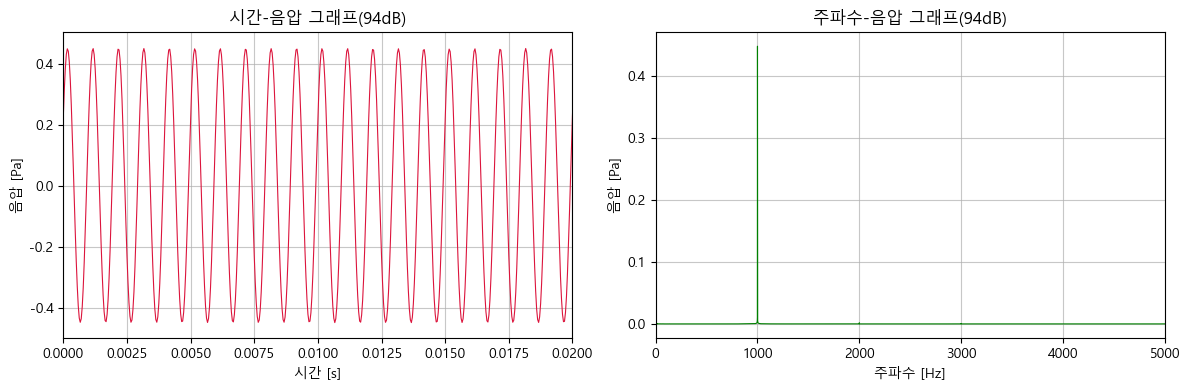

In [25]:
# 두 그래프 병렬 표시
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df_94db['Time'], df_94db['Sound'], color='crimson', linewidth=0.8)
axes[0].set_xlim((0, 0.02))
axes[0].set_title('시간-음압 그래프(94dB)')
axes[0].set_xlabel('시간 [s]')
axes[0].set_ylabel('음압 [Pa]')
axes[0].grid(True, alpha=0.7)

axes[1].plot(f, a, color='green', linewidth=0.8)
axes[1].set_title('주파수-음압 그래프(94dB)')
axes[1].set_xlabel('주파수 [Hz]')
axes[1].set_ylabel('음압 [Pa]')
axes[1].set_xlim(0, 5000)
axes[1].grid(True, alpha=0.7)

plt.tight_layout()
plt.show()

Signal Period: 0.001001 sec


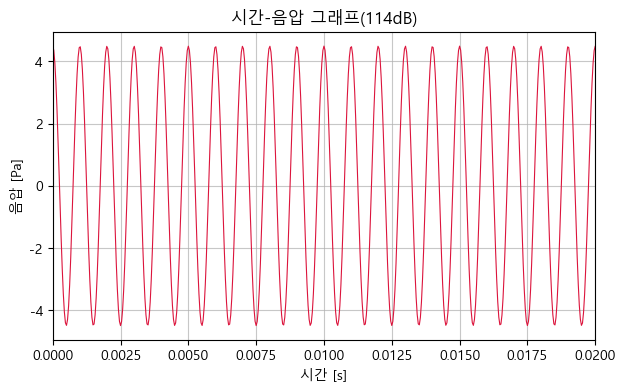

In [26]:
## 시간축 주기 계산
dt = df_114db['Time'].iloc[1] - df_114db['Time'].iloc[0]
N = len(df_114db)
fft_vals = np.fft.fft(df_114db['Sound'] - df_114db['Sound'].mean())
freqs = np.fft.fftfreq(N, dt)
pos = freqs >= 0
amp = np.abs(fft_vals[pos])
peak_freq = freqs[pos][np.argmax(amp[freqs[pos] > 0])]
signal_period = 1 / peak_freq

print(f"Signal Period: {signal_period:.6f} sec")

## 시간축 그래프 그리기
plt.figure(figsize=(7, 4))
plt.plot(df_114db['Time'], df_114db['Sound'], color='crimson', linewidth=0.8)
plt.xlim((0,0.02))
plt.title('시간-음압 그래프(114dB)')
plt.xlabel('시간 [s]')
plt.ylabel('음압 [Pa]')
plt.grid(True, alpha=0.7)
plt.show()

Peak Frequency: 1000.00 Hz | Amplitude: 4.4772 Pa


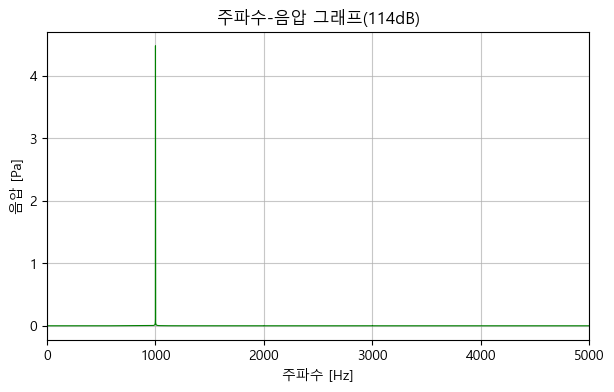

In [27]:
## FFT 진행
N = len(df_114db)
dt = df_114db['Time'].iloc[1] - df_114db['Time'].iloc[0]
fft_vals = np.fft.fft(df_114db['Sound'] - df_114db['Sound'].mean())
freqs = np.fft.fftfreq(N, dt)
pos = freqs >= 0
amp = (2.0 / N) * np.abs(fft_vals[pos])
amp[0] /= 2.0
f, a = freqs[pos], amp
peak_idx = np.argmax(a[f > 0])
peak_freq = f[f > 0][peak_idx]
peak_amp = a[f > 0][peak_idx]
print(f"Peak Frequency: {peak_freq:.2f} Hz | Amplitude: {peak_amp:.4f} Pa")

## 주파수축 그래프 그리기
plt.figure(figsize=(7, 4))
plt.title('주파수-음압 그래프(114dB)')
plt.plot(f, a, color='green', linewidth=0.8)
plt.xlabel('주파수 [Hz]')
plt.ylabel('음압 [Pa]')
plt.grid(True, alpha=0.7)
plt.xlim(0, 5000)
plt.show()

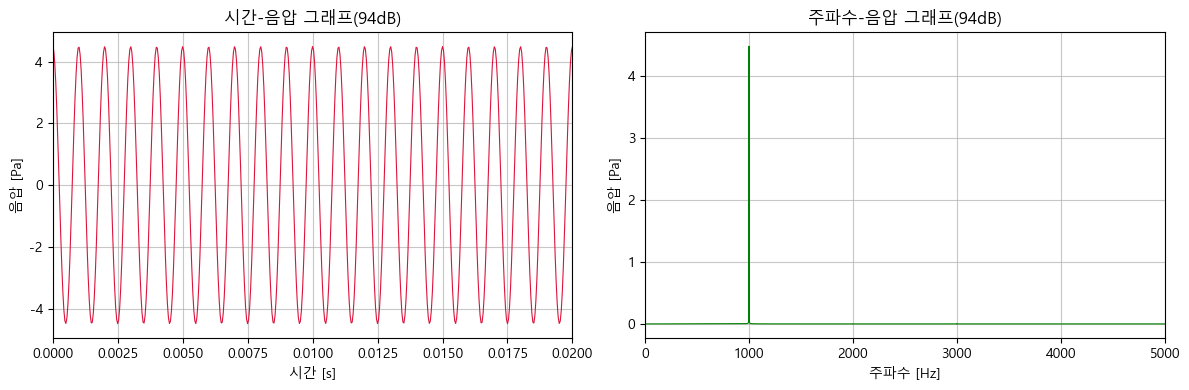

In [28]:
# 두 그래프 병렬 표시
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df_114db['Time'], df_114db['Sound'], color='crimson', linewidth=0.8)
axes[0].set_xlim((0, 0.02))
axes[0].set_title('시간-음압 그래프(94dB)')
axes[0].set_xlabel('시간 [s]')
axes[0].set_ylabel('음압 [Pa]')
axes[0].grid(True, alpha=0.7)

axes[1].plot(f, a, color='green', linewidth=0.8)
axes[1].set_title('주파수-음압 그래프(94dB)')
axes[1].set_xlabel('주파수 [Hz]')
axes[1].set_ylabel('음압 [Pa]')
axes[1].set_xlim(0, 5000)
axes[1].grid(True, alpha=0.7)

plt.tight_layout()
plt.show()

In [64]:
df_94db_filtered = df_94db[(df_94db['Time'] >= 0) & (df_94db['Time'] <= 0.02)]
df_114db_filtered = df_114db[(df_114db['Time'] >= 0) & (df_114db['Time'] <= 0.02)]

rms_94db = np.sqrt(np.mean(df_94db_filtered['Sound']**2))
rms_114db = np.sqrt(np.mean(df_114db_filtered['Sound']**2))

print(f"94dB RMS: {rms_94db:.4f} Pa")
print(f"114dB RMS: {rms_114db:.4f} Pa")

p_ref = 20e-6

db_94 = 20 * np.log10(rms_94db / p_ref)
db_114 = 20 * np.log10(rms_114db / p_ref)

print(f"94dB SPL: {db_94:.2f} dB")
print(f"114dB SPL: {db_114:.2f} dB")

94dB RMS: 0.3165 Pa
114dB RMS: 3.1740 Pa
94dB SPL: 83.99 dB
114dB SPL: 104.01 dB


### **노이즈 데이터 분석**

노이즈가 포함된 데이터의 음향신호 분석 및 FFT

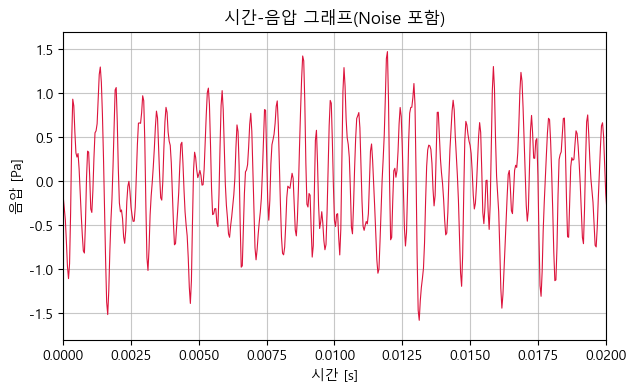

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(df_noise['Time'], df_noise['Sound'], color='crimson', linewidth=0.8)
plt.xlim((0,0.02))
plt.ylim((-1.8,1.8))
plt.title('시간-음압 그래프(Noise 포함)')
plt.xlabel('시간 [s]')
plt.ylabel('음압 [Pa]')
plt.grid(True, alpha=0.7)
plt.show()

Peak 1: 2000.00 Hz | Amplitude: 0.5992 Pa
Peak 2: 3800.00 Hz | Amplitude: 0.2424 Pa
Peak 3: 4900.00 Hz | Amplitude: 0.0956 Pa


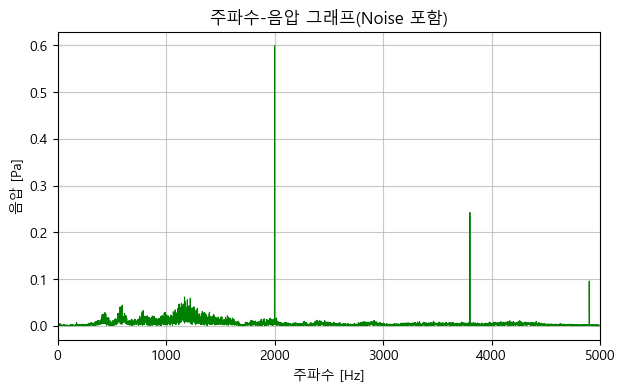

In [39]:
## FFT 진행
N = len(df_noise)
dt = df_noise['Time'].iloc[1] - df_noise['Time'].iloc[0]
fft_vals = np.fft.fft(df_noise['Sound'] - df_noise['Sound'].mean())
freqs = np.fft.fftfreq(N, dt)
pos = freqs >= 0
amp = (2.0 / N) * np.abs(fft_vals[pos])
amp[0] /= 2.0
f, a = freqs[pos], amp

valid = f > 0
f_v, a_v = f[valid], a[valid]
local_max = np.where((a_v[1:-1] > a_v[:-2]) & (a_v[1:-1] > a_v[2:]))[0] + 1
top3_idx = local_max[np.argsort(a_v[local_max])[::-1]][:3]

for i, idx in enumerate(top3_idx):
    print(f"Peak {i+1}: {f_v[idx]:.2f} Hz | Amplitude: {a_v[idx]:.4f} Pa")

## 주파수 그래프
plt.figure(figsize=(7, 4))
plt.title('주파수-음압 그래프(Noise 포함)')
plt.plot(f, a, color='green', linewidth=0.8)
plt.xlabel('주파수 [Hz]')
plt.ylabel('음압 [Pa]')
plt.grid(True, alpha=0.7)
plt.xlim(0, 5000)
plt.show()

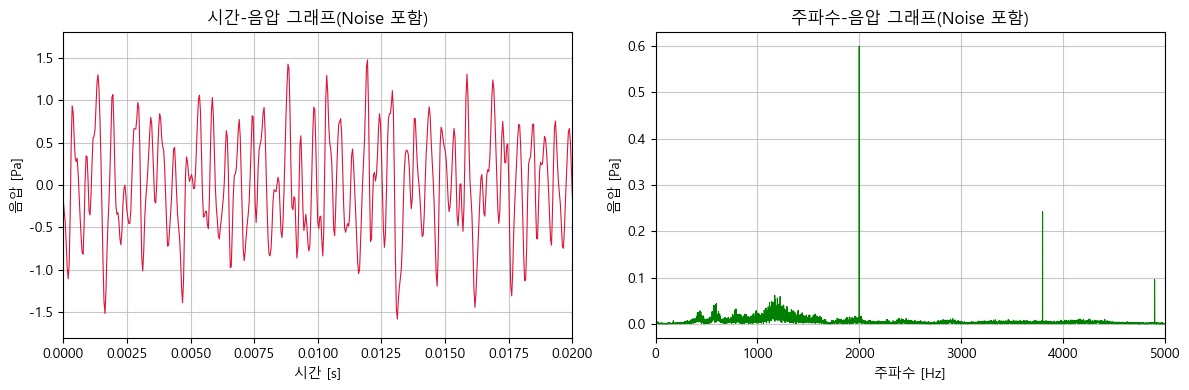

In [58]:
# 두 그래프 병렬 표시
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df_noise['Time'], df_noise['Sound'], color='crimson', linewidth=0.8)
axes[0].set_xlim((0, 0.02))
axes[0].set_ylim((-1.8,1.8))
axes[0].set_title('시간-음압 그래프(Noise 포함)')
axes[0].set_xlabel('시간 [s]')
axes[0].set_ylabel('음압 [Pa]')
axes[0].grid(True, alpha=0.7)

axes[1].plot(f, a, color='green', linewidth=0.8)
axes[1].set_title('주파수-음압 그래프(Noise 포함)')
axes[1].set_xlabel('주파수 [Hz]')
axes[1].set_ylabel('음압 [Pa]')
axes[1].set_xlim(0, 5000)
axes[1].grid(True, alpha=0.7)

plt.tight_layout()
plt.show()

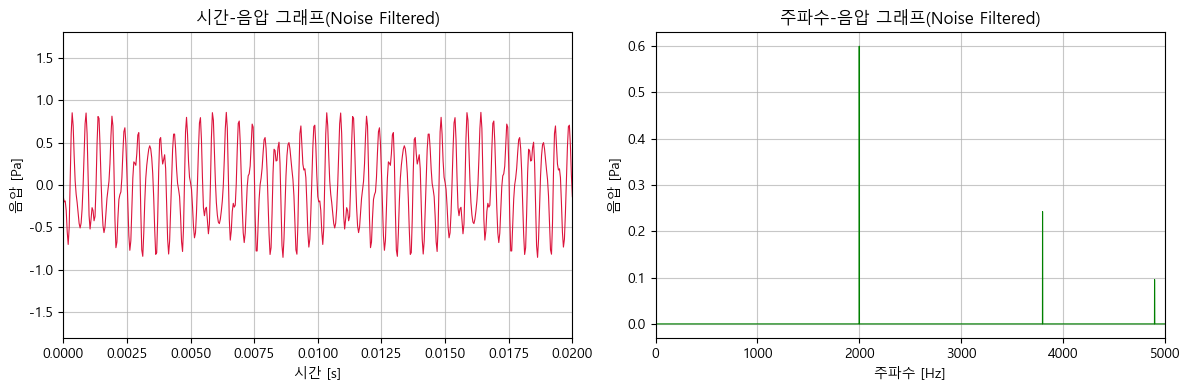

In [52]:
## 상위 3개 피크 주파수만 남기고 IFFT로 시간 신호 재구성
fft_filtered = np.zeros_like(fft_vals, dtype=complex)
for idx in top3_idx:
    target_freq = f_v[idx]
    match_indices = np.where(np.isclose(freqs, target_freq, atol=1e-5))[0]
    for m_idx in match_indices:
        fft_filtered[m_idx] = fft_vals[m_idx]
        neg_idx = (N - m_idx) % N
        fft_filtered[neg_idx] = fft_vals[neg_idx]

sound_filtered = np.real(np.fft.ifft(fft_filtered)) + df_noise['Sound'].mean()

df_filtered = pd.DataFrame({
    'Time': df_noise['Time'],
    'Sound': sound_filtered
})

## 새로운 FFT 수행 (중복 방지를 위해 _new 변수 사용)
N_new = len(df_filtered)
dt_new = df_filtered['Time'].iloc[1] - df_filtered['Time'].iloc[0]
fft_vals_new = np.fft.fft(df_filtered['Sound'] - df_filtered['Sound'].mean())
freqs_new = np.fft.fftfreq(N_new, dt_new)
pos_new = freqs_new >= 0
amp_new = (2.0 / N_new) * np.abs(fft_vals_new[pos_new])
amp_new[0] /= 2.0
f_new, a_new = freqs_new[pos_new], amp_new

## 시간축 및 주파수축 그래프 나란히 표시
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df_filtered['Time'], df_filtered['Sound'], color='crimson', linewidth=0.8)
axes[0].set_xlim((0, 0.02))
axes[0].set_ylim((-1.8,1.8))
axes[0].set_title('시간-음압 그래프(Noise Filtered)')
axes[0].set_xlabel('시간 [s]')
axes[0].set_ylabel('음압 [Pa]')
axes[0].grid(True, alpha=0.7)

axes[1].plot(f_new, a_new, color='green', linewidth=0.8)
axes[1].set_title('주파수-음압 그래프(Noise Filtered)')
axes[1].set_xlabel('주파수 [Hz]')
axes[1].set_ylabel('음압 [Pa]')
axes[1].set_xlim(0, 5000)
axes[1].grid(True, alpha=0.7)

plt.tight_layout()
plt.show()

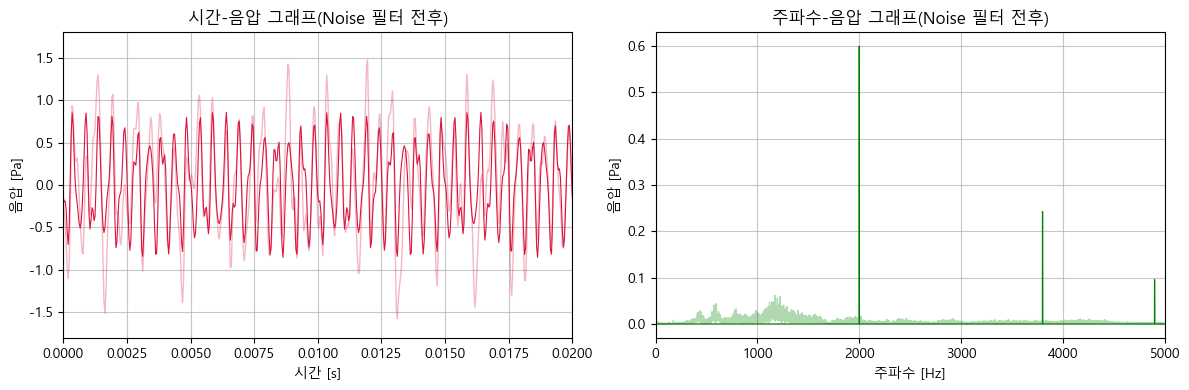

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df_noise['Time'], df_noise['Sound'], color='crimson', linewidth=1, alpha=0.3)
axes[0].plot(df_filtered['Time'], df_filtered['Sound'], color='crimson', linewidth=0.8)
axes[0].set_xlim((0, 0.02))
axes[0].set_ylim((-1.8, 1.8))
axes[0].set_title('시간-음압 그래프(Noise 필터 전후)')
axes[0].set_xlabel('시간 [s]')
axes[0].set_ylabel('음압 [Pa]')
axes[0].grid(True, alpha=0.7)

axes[1].plot(f, a, color='green', linewidth=1, alpha=0.3)
axes[1].plot(f_new, a_new, color='green', linewidth=0.8)
axes[1].set_title('주파수-음압 그래프(Noise 필터 전후)')
axes[1].set_xlabel('주파수 [Hz]')
axes[1].set_ylabel('음압 [Pa]')
axes[1].set_xlim(0, 5000)
axes[1].grid(True, alpha=0.7)

plt.tight_layout()
plt.show()